In [1]:
import mysql.connector
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="sales_management"
)

print("MySQL connection successful!")

MySQL connection successful!


In [4]:
cursor = connection.cursor()

cursor.execute("SELECT DATABASE();")

result = cursor.fetchone()

print("Connected database:", result[0])

Connected database: sales_management


In [5]:
query = """
SELECT *
FROM customer_sales;
"""

df_sales = pd.read_sql(query, connection)

df_sales.head()

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1714233072.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sales = pd.read_sql(query, connection)


,sale_id,branch_id,date,name,mobile_number,product_name,gross_sales,received_amount,pending_amount,status
0,1,2,2024-01-02,Customer_1,9800000001,DS,40000.0,7296.0,32704.0,Open
1,2,5,2024-01-03,Customer_2,9800000002,BA,30000.0,7314.0,22686.0,Open
2,3,4,2024-01-04,Customer_3,9800000003,DA,35000.0,5697.0,29303.0,Open
3,4,2,2024-01-05,Customer_4,9800000004,FSD,45000.0,1739.0,43261.0,Open
4,5,7,2024-01-06,Customer_5,9800000005,DS,40000.0,18231.0,21769.0,Open


In [6]:
# Load branches
df_branches = pd.read_sql(
    "SELECT * FROM branches;",
    connection
)

# Load users
df_users = pd.read_sql(
    "SELECT * FROM users;",
    connection
)

# Load payment splits
df_payments = pd.read_sql(
    "SELECT * FROM payment_splits;",
    connection
)

# Check the size of each dataset
print("Branches :", df_branches.shape)
print("Sales    :", df_sales.shape)
print("Users    :", df_users.shape)
print("Payments :", df_payments.shape)

Branches : (8, 3)
Sales    : (1000, 10)
Users    : (9, 6)
Payments : (2011, 5)


C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1063350755.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_branches = pd.read_sql(
C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1063350755.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_users = pd.read_sql(
C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1063350755.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_payments = pd.read_sql(


In [7]:
print("Branches")
display(df_branches.head())

print("Sales")
display(df_sales.head())

print("Users")
display(df_users.head())

print("Payments")
display(df_payments.head())

Branches


,branch_id,branch_name,branch_admin_name
0,1,Chennai,Arun Kumar
1,2,Bangalore,Ravi Shankar
2,3,Hyderabad,Suresh Reddy
3,4,Delhi,Neha Sharma
4,5,Mumbai,Rahul Mehta


Sales


,sale_id,branch_id,date,name,mobile_number,product_name,gross_sales,received_amount,pending_amount,status
0,1,2,2024-01-02,Customer_1,9800000001,DS,40000.0,7296.0,32704.0,Open
1,2,5,2024-01-03,Customer_2,9800000002,BA,30000.0,7314.0,22686.0,Open
2,3,4,2024-01-04,Customer_3,9800000003,DA,35000.0,5697.0,29303.0,Open
3,4,2,2024-01-05,Customer_4,9800000004,FSD,45000.0,1739.0,43261.0,Open
4,5,7,2024-01-06,Customer_5,9800000005,DS,40000.0,18231.0,21769.0,Open


Users


,user_id,username,password,branch_id,role,email
0,1,superadmin,super123,NaN,Super Admin,superadmin@company.com
1,2,admin_chennai,admin123,1.0,Admin,chennai@company.com
2,3,admin_bangalore,admin123,2.0,Admin,bangalore@company.com
3,4,admin_hyderabad,admin123,3.0,Admin,hyderabad@company.com
4,5,admin_delhi,admin123,4.0,Admin,delhi@company.com


Payments


,payment_id,sale_id,payment_date,amount_paid,payment_method
0,1,1,2024-01-06,7296.0,Cash
1,2,2,2024-01-04,7314.0,Card
2,3,3,2024-01-04,3457.0,Cash
3,4,3,2024-01-07,384.0,Cash
4,5,3,2024-01-12,1856.0,Card


In [8]:
total_gross_sales = df_sales["gross_sales"].sum()

print("Total Gross Sales:", total_gross_sales)

Total Gross Sales: 36768000.0


In [9]:
total_received = df_sales["received_amount"].sum()

print("Total Received:", total_received)

Total Received: 19028113.0


In [10]:
total_pending = df_sales["pending_amount"].sum()

print("Total Pending:", total_pending)

Total Pending: 17739887.0


In [11]:
print("================================")
print("      SALES SUMMARY")
print("================================")
print(f"Total Gross Sales : ₹{total_gross_sales:,.2f}")
print(f"Total Received    : ₹{total_received:,.2f}")
print(f"Total Pending     : ₹{total_pending:,.2f}")
print("================================")

      SALES SUMMARY
Total Gross Sales : ₹36,768,000.00
Total Received    : ₹19,028,113.00
Total Pending     : ₹17,739,887.00


In [12]:
branch_sales_query = """
SELECT
    b.branch_id,
    b.branch_name,
    SUM(cs.gross_sales) AS total_sales
FROM branches b
JOIN customer_sales cs
    ON b.branch_id = cs.branch_id
GROUP BY
    b.branch_id,
    b.branch_name
ORDER BY total_sales DESC;
"""

branch_sales = pd.read_sql(branch_sales_query, connection)

branch_sales

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\3178692273.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  branch_sales = pd.read_sql(branch_sales_query, connection)


,branch_id,branch_name,total_sales
0,7,Kolkata,5101000.0
1,4,Delhi,4914000.0
2,5,Mumbai,4853000.0
3,2,Bangalore,4710000.0
4,8,Ahmedabad,4695000.0
5,6,Pune,4558000.0
6,1,Chennai,4128000.0
7,3,Hyderabad,3809000.0


In [13]:
top_branch = branch_sales.iloc[0]

print("Highest Sales Branch:", top_branch["branch_name"])
print("Total Sales:", f"₹{top_branch['total_sales']:,.2f}")

Highest Sales Branch: Kolkata
Total Sales: ₹5,101,000.00


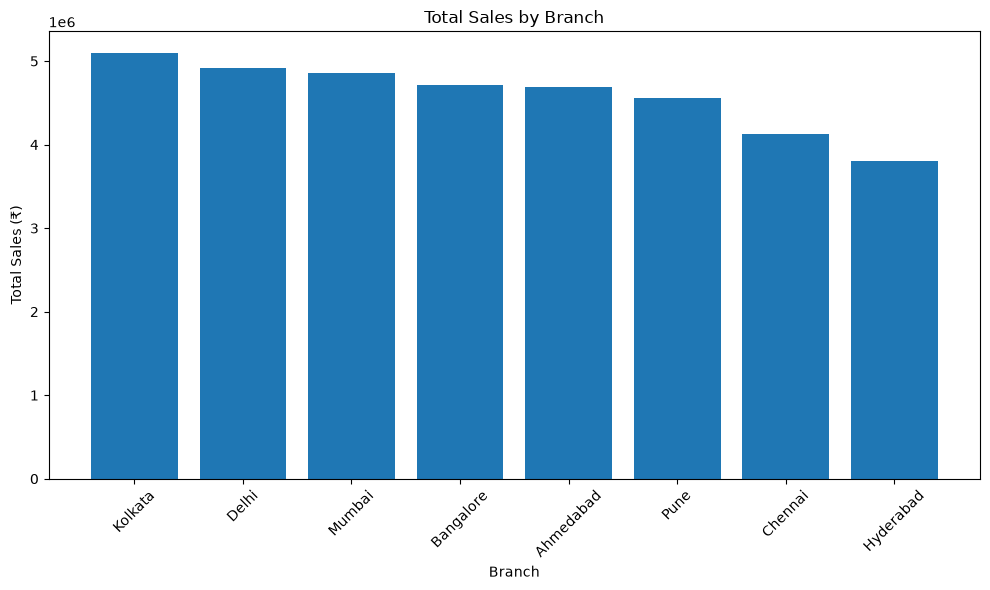

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    branch_sales["branch_name"],
    branch_sales["total_sales"]
)

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
branch_sales["sales_percentage"] = (
    branch_sales["total_sales"]
    / branch_sales["total_sales"].sum()
) * 100

branch_sales

,branch_id,branch_name,total_sales,sales_percentage
0,7,Kolkata,5101000.0,13.873477
1,4,Delhi,4914000.0,13.364883
2,5,Mumbai,4853000.0,13.198977
3,2,Bangalore,4710000.0,12.810052
4,8,Ahmedabad,4695000.0,12.769256
5,6,Pune,4558000.0,12.396649
6,1,Chennai,4128000.0,11.227154
7,3,Hyderabad,3809000.0,10.359552


In [16]:
payment_method_query = """
SELECT
    payment_method,
    COUNT(*) AS number_of_payments,
    SUM(amount_paid) AS total_collection
FROM payment_splits
GROUP BY payment_method
ORDER BY total_collection DESC;
"""

payment_analysis = pd.read_sql(
    payment_method_query,
    connection
)

payment_analysis

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1869899776.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  payment_analysis = pd.read_sql(


,payment_method,number_of_payments,total_collection
0,Card,695,6608008.0
1,Cash,669,6387006.0
2,UPI,647,6033099.0


In [17]:
payment_analysis["collection_percentage"] = (
    payment_analysis["total_collection"]
    / payment_analysis["total_collection"].sum()
) * 100

payment_analysis

,payment_method,number_of_payments,total_collection,collection_percentage
0,Card,695,6608008.0,34.727605
1,Cash,669,6387006.0,33.566156
2,UPI,647,6033099.0,31.706239


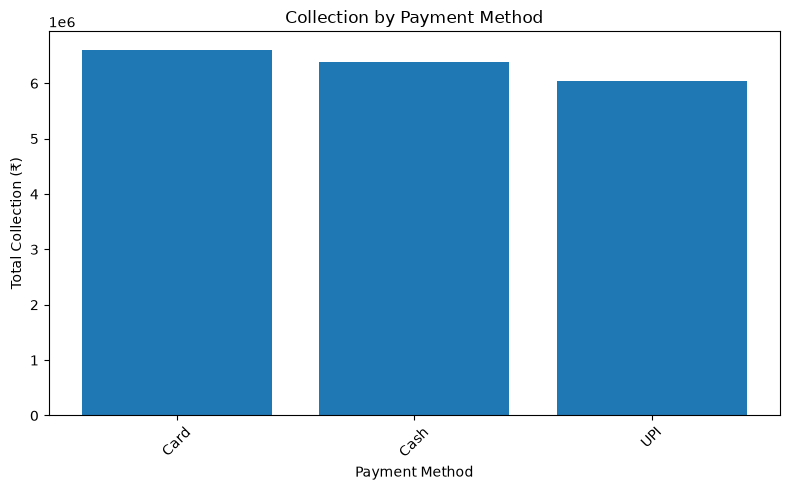

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["total_collection"]
)

plt.title("Collection by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Collection (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
monthly_sales_query = """
SELECT
    YEAR(date) AS year,
    MONTH(date) AS month,
    DATE_FORMAT(date, '%Y-%m') AS month_name,
    SUM(gross_sales) AS total_sales
FROM customer_sales
GROUP BY
    YEAR(date),
    MONTH(date),
    DATE_FORMAT(date, '%Y-%m')
ORDER BY
    year,
    month;
"""

monthly_sales = pd.read_sql(
    monthly_sales_query,
    connection
)

monthly_sales

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\2030673234.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly_sales = pd.read_sql(


,year,month,month_name,total_sales
0,2024,1,2024-01,3487000.0
1,2024,2,2024-02,3116000.0
2,2024,3,2024-03,3442000.0
3,2024,4,2024-04,3272000.0
4,2024,5,2024-05,3418000.0
5,2024,6,2024-06,3294000.0
6,2024,7,2024-07,3517000.0
7,2024,8,2024-08,3254000.0
8,2024,9,2024-09,3183000.0
9,2024,10,2024-10,2362000.0


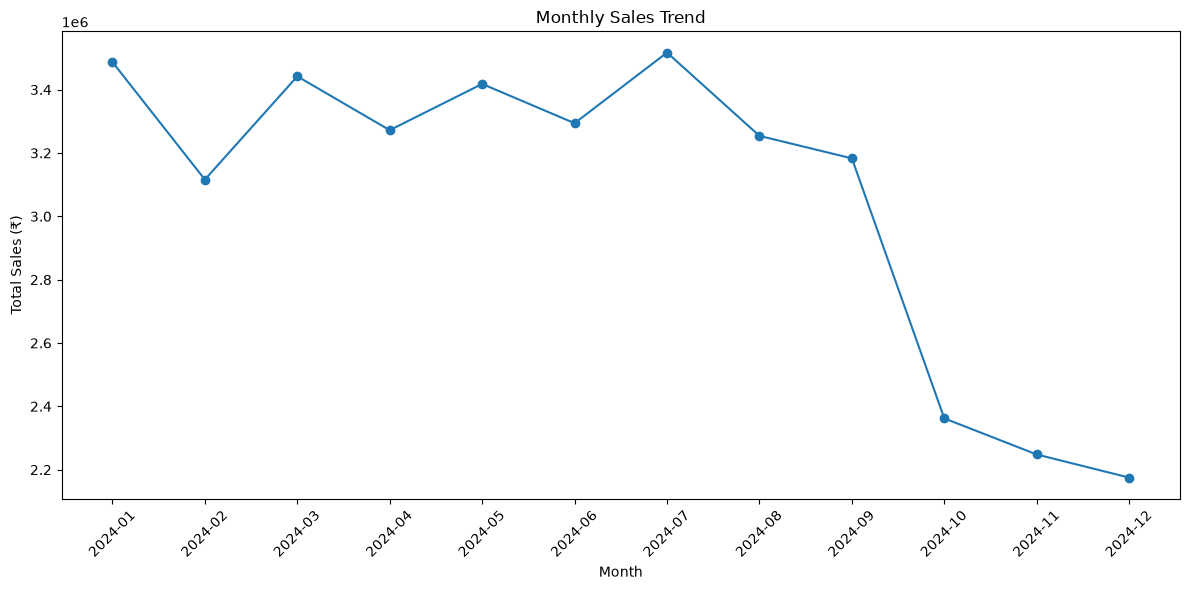

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["month_name"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
best_month = monthly_sales.loc[
    monthly_sales["total_sales"].idxmax()
]

print("Best Sales Month:", best_month["month_name"])
print("Sales:", f"₹{best_month['total_sales']:,.2f}")

Best Sales Month: 2024-07
Sales: ₹3,517,000.00


In [22]:
lowest_month = monthly_sales.loc[
    monthly_sales["total_sales"].idxmin()
]

print("Lowest Sales Month:", lowest_month["month_name"])
print("Sales:", f"₹{lowest_month['total_sales']:,.2f}")

Lowest Sales Month: 2024-12
Sales: ₹2,175,000.00


In [23]:
product_sales_query = """
SELECT
    product_name,
    COUNT(*) AS number_of_sales,
    SUM(gross_sales) AS total_sales
FROM customer_sales
GROUP BY product_name
ORDER BY total_sales DESC;
"""

product_sales = pd.read_sql(
    product_sales_query,
    connection
)

product_sales

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\4040076430.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  product_sales = pd.read_sql(


,product_name,number_of_sales,total_sales
0,AI,133,6384000.0
1,FSD,127,5715000.0
2,ML,127,5334000.0
3,DA,133,4655000.0
4,DS,114,4560000.0
5,BI,140,3920000.0
6,BA,110,3300000.0
7,SQL,116,2900000.0


In [24]:
product_sales["sales_percentage"] = (
    product_sales["total_sales"]
    / product_sales["total_sales"].sum()
) * 100

product_sales

,product_name,number_of_sales,total_sales,sales_percentage
0,AI,133,6384000.0,17.362924
1,FSD,127,5715000.0,15.543407
2,ML,127,5334000.0,14.507180
3,DA,133,4655000.0,12.660466
4,DS,114,4560000.0,12.402089
5,BI,140,3920000.0,10.661445
6,BA,110,3300000.0,8.975196
7,SQL,116,2900000.0,7.887293


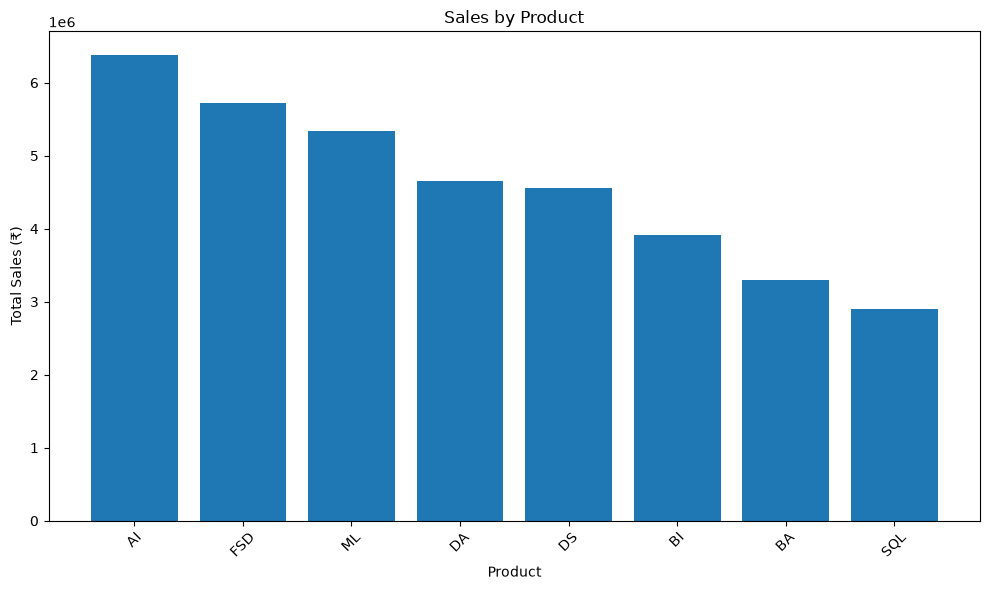

In [25]:
plt.figure(figsize=(10, 6))

plt.bar(
    product_sales["product_name"],
    product_sales["total_sales"]
)

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
best_product = product_sales.iloc[0]

print("Best Selling Product:", best_product["product_name"])
print("Total Sales:", f"₹{best_product['total_sales']:,.2f}")
print("Sales Contribution:", f"{best_product['sales_percentage']:.2f}%")

Best Selling Product: AI
Total Sales: ₹6,384,000.00
Sales Contribution: 17.36%


In [27]:
pending_customers_query = """
SELECT
    sale_id,
    name AS customer_name,
    mobile_number,
    gross_sales,
    received_amount,
    pending_amount,
    status
FROM customer_sales
WHERE pending_amount > 0
ORDER BY pending_amount DESC;
"""

pending_customers = pd.read_sql(
    pending_customers_query,
    connection
)

pending_customers.head(10)

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1994003168.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pending_customers = pd.read_sql(


,sale_id,customer_name,mobile_number,gross_sales,received_amount,pending_amount,status
0,598,Customer_598,9800000598,48000.0,44.0,47956.0,Open
1,369,Customer_369,9800000369,48000.0,339.0,47661.0,Open
2,748,Customer_748,9800000748,48000.0,369.0,47631.0,Open
3,658,Customer_658,9800000658,48000.0,554.0,47446.0,Open
4,244,Customer_244,9800000244,48000.0,1228.0,46772.0,Open
5,650,Customer_650,9800000650,48000.0,2002.0,45998.0,Open
6,648,Customer_648,9800000648,48000.0,2167.0,45833.0,Open
7,780,Customer_780,9800000780,45000.0,316.0,44684.0,Open
8,426,Customer_426,9800000426,45000.0,418.0,44582.0,Open
9,859,Customer_859,9800000859,45000.0,638.0,44362.0,Open


In [28]:
highest_pending = pending_customers.iloc[0]

print("Customer:", highest_pending["customer_name"])
print("Sale ID:", highest_pending["sale_id"])
print("Gross Sales:", f"₹{highest_pending['gross_sales']:,.2f}")
print("Received:", f"₹{highest_pending['received_amount']:,.2f}")
print("Pending:", f"₹{highest_pending['pending_amount']:,.2f}")

Customer: Customer_598
Sale ID: 598
Gross Sales: ₹48,000.00
Received: ₹44.00
Pending: ₹47,956.00


In [29]:
status_analysis = df_sales.groupby("status").agg(
    number_of_sales=("sale_id", "count"),
    total_sales=("gross_sales", "sum"),
    total_received=("received_amount", "sum"),
    total_pending=("pending_amount", "sum")
).reset_index()

status_analysis

,status,number_of_sales,total_sales,total_received,total_pending
0,Open,1000,36768000.0,19028113.0,17739887.0


In [30]:
branch_pending_query = """
SELECT
    b.branch_name,
    SUM(cs.gross_sales) AS total_sales,
    SUM(cs.received_amount) AS total_received,
    SUM(cs.pending_amount) AS total_pending
FROM branches b
JOIN customer_sales cs
    ON b.branch_id = cs.branch_id
GROUP BY
    b.branch_id,
    b.branch_name
ORDER BY total_pending DESC;
"""

branch_pending = pd.read_sql(
    branch_pending_query,
    connection
)

branch_pending

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\2908767692.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  branch_pending = pd.read_sql(


,branch_name,total_sales,total_received,total_pending
0,Kolkata,5101000.0,2461416.0,2639584.0
1,Delhi,4914000.0,2333104.0,2580896.0
2,Bangalore,4710000.0,2394709.0,2315291.0
3,Ahmedabad,4695000.0,2482989.0,2212011.0
4,Mumbai,4853000.0,2649828.0,2203172.0
5,Pune,4558000.0,2401785.0,2156215.0
6,Chennai,4128000.0,2275748.0,1852252.0
7,Hyderabad,3809000.0,2028534.0,1780466.0


In [31]:
pending_customers_query = """
SELECT
    sale_id,
    name AS customer_name,
    mobile_number,
    gross_sales,
    received_amount,
    pending_amount,
    status
FROM customer_sales
WHERE pending_amount > 0
ORDER BY pending_amount DESC;
"""

pending_customers = pd.read_sql(
    pending_customers_query,
    connection
)

pending_customers.head(10)

C:\Users\this pc\AppData\Local\Temp\ipykernel_21428\1994003168.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pending_customers = pd.read_sql(


,sale_id,customer_name,mobile_number,gross_sales,received_amount,pending_amount,status
0,598,Customer_598,9800000598,48000.0,44.0,47956.0,Open
1,369,Customer_369,9800000369,48000.0,339.0,47661.0,Open
2,748,Customer_748,9800000748,48000.0,369.0,47631.0,Open
3,658,Customer_658,9800000658,48000.0,554.0,47446.0,Open
4,244,Customer_244,9800000244,48000.0,1228.0,46772.0,Open
5,650,Customer_650,9800000650,48000.0,2002.0,45998.0,Open
6,648,Customer_648,9800000648,48000.0,2167.0,45833.0,Open
7,780,Customer_780,9800000780,45000.0,316.0,44684.0,Open
8,426,Customer_426,9800000426,45000.0,418.0,44582.0,Open
9,859,Customer_859,9800000859,45000.0,638.0,44362.0,Open


In [32]:
highest_pending = pending_customers.iloc[0]

print("Highest Pending Customer")
print("-----------------------")
print("Customer :", highest_pending["customer_name"])
print("Sale ID  :", highest_pending["sale_id"])
print("Gross    :", f"₹{highest_pending['gross_sales']:,.2f}")
print("Received :", f"₹{highest_pending['received_amount']:,.2f}")
print("Pending  :", f"₹{highest_pending['pending_amount']:,.2f}")

Highest Pending Customer
-----------------------
Customer : Customer_598
Sale ID  : 598
Gross    : ₹48,000.00
Received : ₹44.00
Pending  : ₹47,956.00


In [33]:
status_analysis = df_sales.groupby("status").agg(
    number_of_sales=("sale_id", "count"),
    total_sales=("gross_sales", "sum"),
    total_received=("received_amount", "sum"),
    total_pending=("pending_amount", "sum")
).reset_index()

status_analysis

,status,number_of_sales,total_sales,total_received,total_pending
0,Open,1000,36768000.0,19028113.0,17739887.0
